In [14]:
!nvidia-smi

Thu Oct 22 11:49:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   76C    P0             33W /   70W |     231MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Zadanie 1

In [6]:
import numpy as np
import time
N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
start = time.time()
C_cpu = np.matmul(A_cpu, B_cpu)
end = time.time()
print(f"Mnożenie macierzy na CPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na CPU trwało: 0.01834 sekund.


In [29]:
import cupy as cp
import time
N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
A_gpu = cp.array(A_cpu)
B_gpu = cp.array(B_cpu)
start = time.time()
C_gpu = cp.matmul(A_gpu, B_gpu)
cp.cuda.Stream.null.synchronize()  # Synchronizacja z GPU
end = time.time()

del A_gpu
del B_gpu
del C_gpu
print(f"Mnożenie macierzy na GPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na GPU trwało: 0.00117 sekund.


Zadanie 2

In [19]:
import numpy as np
import time
import locale
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if (row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

N = 1024

A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
C_cpu = np.empty((N, N), np.float32)

A_gpu = cuda.mem_alloc(A_cpu.nbytes)
B_gpu = cuda.mem_alloc(B_cpu.nbytes)
C_gpu = cuda.mem_alloc(C_cpu.nbytes)

cuda.memcpy_htod(A_gpu, A_cpu)
cuda.memcpy_htod(B_gpu, B_cpu)

block_size = (32, 32, 1)
grid_size = (int(np.ceil(N / 32)), int(np.ceil(N / 32)), 1)

start = time.time()
matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_size, grid=grid_size)
cuda.Context.synchronize()
end = time.time()

cuda.memcpy_dtoh(C_cpu, C_gpu)

print(f"Mnożenie macierzy w PyCUDA trwało: {end - start:.5f} sekund.")

del A_gpu
del B_gpu
del C_gpu

Mnożenie macierzy w PyCUDA trwało: 0.00691 sekund.


Zadanie 3

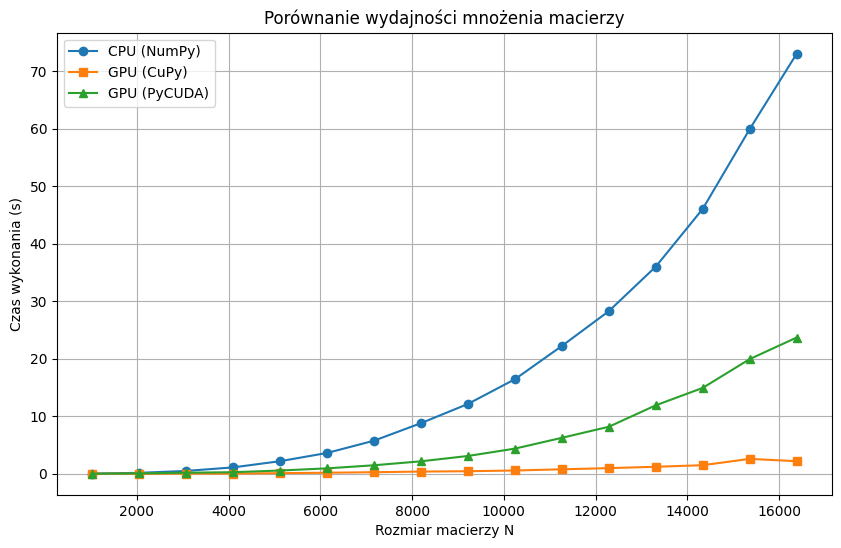

In [32]:
import numpy as np
import cupy as cp
import time
import locale
import matplotlib.pyplot as plt
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule


kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if (row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

sizes = []
times_cpu = []
times_cupy = []
times_pycuda = []

for i in range(1,17):
  N = 1024 * i
  sizes.append(N)

  A_cpu = np.random.rand(N, N).astype(np.float32)
  B_cpu = np.random.rand(N, N).astype(np.float32)

  #cpu
  start = time.time()
  C_cpu = np.matmul(A_cpu, B_cpu)
  end = time.time()
  times_cpu.append(end - start)

  #gpu
  A_gpu = cp.array(A_cpu)
  B_gpu = cp.array(B_cpu)
  start = time.time()
  C_gpu = cp.matmul(A_gpu, B_gpu)
  cp.cuda.Stream.null.synchronize()
  end = time.time()
  times_cupy.append(end - start)

  del A_gpu
  del B_gpu
  del C_gpu

  #pycuda
  C_pycuda = np.empty((N, N), np.float32)
  A_cuda = cuda.mem_alloc(A_cpu.nbytes)
  B_cuda = cuda.mem_alloc(B_cpu.nbytes)
  C_cuda = cuda.mem_alloc(C_pycuda.nbytes)

  cuda.memcpy_htod(A_cuda, A_cpu)
  cuda.memcpy_htod(B_cuda, B_cpu)

  block_size = (32, 32, 1)
  grid_size = (int(np.ceil(N / 32)), int(np.ceil(N / 32)), 1)

  start = time.time()
  matrixMul(A_cuda, B_cuda, C_cuda, np.int32(N), block=block_size, grid=grid_size)
  cuda.Context.synchronize()
  end = time.time()
  times_pycuda.append(end - start)

  cuda.memcpy_dtoh(C_pycuda, C_cuda)

  del A_cuda
  del B_cuda
  del C_cuda

plt.figure(figsize=(10, 6))
plt.plot(sizes, times_cpu, label="CPU (NumPy)", marker="o")
plt.plot(sizes, times_cupy, label="GPU (CuPy)", marker="s")
plt.plot(sizes, times_pycuda, label="GPU (PyCUDA)", marker="^")
plt.xlabel("Rozmiar macierzy N")
plt.ylabel("Czas wykonania (s)")
plt.title("Porównanie wydajności mnożenia macierzy")
plt.legend()
plt.grid(True)
plt.show()